# Customer Churn Analysis and Prediction

## Business Objective

Customer churn is a major challenge for subscription businesses. 
The goal of this project is to analyze customer behavior, identify factors influencing churn, and build a machine learning model to predict customers at risk of leaving.

## Business Questions

1. Why are customers leaving?
2. Which customer segments have the highest churn risk?
3. What factors influence customer churn?
4. Can we predict customers who are likely to churn?
5. What actions can reduce churn?

## Project Workflow

- Data Understanding
- Data Cleaning
- Exploratory Data Analysis
- Machine Learning Prediction
- Customer Risk Segmentation
- Business Recommendations
- Power BI Dashboard

In [1]:
#1. Import Libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")


# Visualization style
sns.set_style("whitegrid")

In [2]:
# 2. Load Dataset
df =pd.read_excel("Telco_customer_churn.xlsx")
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## 3. Data Understanding

The first step is understanding the dataset structure, variables, and data quality.

This helps identify:
- incorrect data types
- missing values
- duplicate records
- potential issues before analysis

In [3]:
df.shape

(7043, 33)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [5]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [6]:
df.describe(include="object")

,CustomerID,Country,State,City,Lat Long,Gender,Senior Citizen,Partner,Dependents,Phone Service,...,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Total Charges,Churn Label,Churn Reason
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043,7043,1869
unique,7043,1,1,1129,1652,2,2,2,2,2,...,3,3,3,3,3,2,4,6531,2,20
top,3186-AJIEK,United States,California,Los Angeles,"34.159534, -116.425984",Male,No,No,No,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,,No,Attitude of support person
freq,1,7043,7043,305,5,3555,5901,3641,5416,6361,...,3095,3473,2810,2785,3875,4171,2365,11,5174,192


In [ ]:
# Data Quality Assessment

In [7]:
df.isnull().sum().sort_values(ascending=False)

Churn Reason         5174
CustomerID              0
Count                   0
State                   0
Country                 0
Zip Code                0
Lat Long                0
Latitude                0
City                    0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Longitude               0
Internet Service        0
Online Security         0
Device Protection       0
Online Backup           0
Streaming TV            0
Streaming Movies        0
Contract                0
Tech Support            0
Paperless Billing       0
Payment Method          0
Total Charges           0
Monthly Charges         0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Churn Label"].value_counts()

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [10]:
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce"
)

In [11]:
df["Total Charges"].isnull().sum()

np.int64(11)

In [12]:
df["Total Charges"] = df["Total Charges"].fillna(0)

In [13]:
drop_columns = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "Lat Long",
    "Churn Score",
    "Churn Reason"
]

df_clean = df.drop(columns=drop_columns)

In [14]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   City               7043 non-null   object 
 1   Zip Code           7043 non-null   int64  
 2   Latitude           7043 non-null   float64
 3   Longitude          7043 non-null   float64
 4   Gender             7043 non-null   object 
 5   Senior Citizen     7043 non-null   object 
 6   Partner            7043 non-null   object 
 7   Dependents         7043 non-null   object 
 8   Tenure Months      7043 non-null   int64  
 9   Phone Service      7043 non-null   object 
 10  Multiple Lines     7043 non-null   object 
 11  Internet Service   7043 non-null   object 
 12  Online Security    7043 non-null   object 
 13  Online Backup      7043 non-null   object 
 14  Device Protection  7043 non-null   object 
 15  Tech Support       7043 non-null   object 
 16  Streaming TV       7043 

In [15]:
def tenure_group(x):
    if x <= 12:
        return "New Customer"
    elif x <= 48:
        return "Established Customer"
    else:
        return "Loyal Customer"


df_clean["Tenure Group"] = df_clean["Tenure Months"].apply(
    tenure_group
)

In [16]:
service_columns = [
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies"
]

df_clean["Number of Services"] = (
    df_clean[service_columns]
    .replace("No internet service","No")
    .eq("Yes")
    .sum(axis=1)
)

# 4. Exploratory Data Analysis (EDA)

The objective of this section is to identify patterns and factors associated with customer churn.

Key questions:

- What is the overall churn rate?
- Which customer groups churn the most?
- Which services are associated with higher retention?
- What customer behaviors indicate churn risk?

In [17]:
#How many customers are leaving the company?
churn_count = df_clean["Churn Label"].value_counts()
churn_count

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

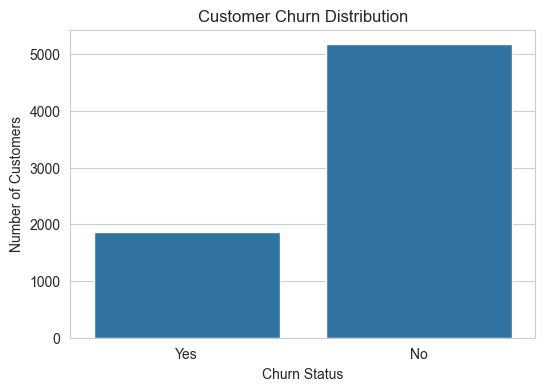

In [18]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df_clean,
    x="Churn Label"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

### Insight

Approximately 26.5% of customers have churned.

This indicates that customer retention is a significant business challenge.
The company should identify high-risk segments and develop targeted retention strategies.

In [19]:
#Are customers with shorter contracts more likely to leave?
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

contract_churn

Churn Label,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


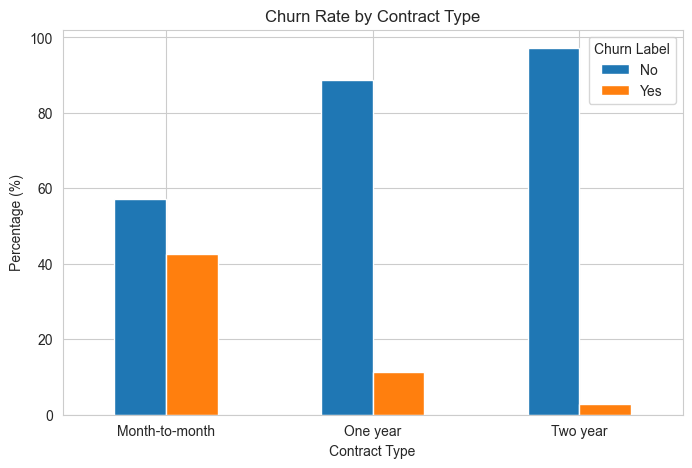

In [20]:
contract_churn.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Churn Rate by Contract Type")
plt.ylabel("Percentage (%)")
plt.xlabel("Contract Type")

plt.xticks(rotation=0)

plt.show()

### Insight

Customers with month-to-month contracts have significantly higher churn rates.

Long-term contracts appear to increase customer commitment and reduce churn risk.

Recommendation:
Encourage customers to move from monthly contracts to yearly plans through loyalty incentives.

In [21]:
#Are newer customers more likely to leave?
tenure_churn = pd.crosstab(
    df_clean["Tenure Group"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

tenure_churn

Churn Label,No,Yes
Tenure Group,,
Established Customer,76.355997,23.644003
Loyal Customer,90.486824,9.513176
New Customer,52.561757,47.438243


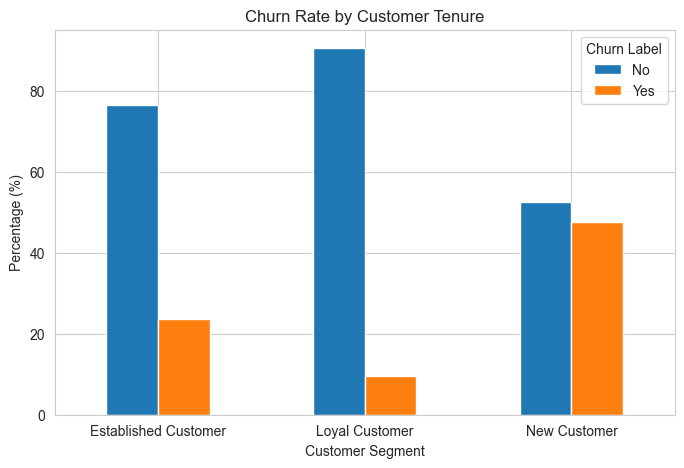

In [22]:
tenure_churn.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Churn Rate by Customer Tenure")
plt.ylabel("Percentage (%)")
plt.xlabel("Customer Segment")

plt.xticks(rotation=0)

plt.show()

### Insight

New customers have the highest churn rate.

This suggests the first months of the customer journey are critical.

Recommendation:
Introduce stronger onboarding programs, early customer support, and satisfaction checks.

In [23]:
#Are higher-paying customers more likely to leave?
df_clean.groupby(
    "Churn Label"
)["Monthly Charges"].mean()

Churn Label
No     61.265124
Yes    74.441332
Name: Monthly Charges, dtype: float64

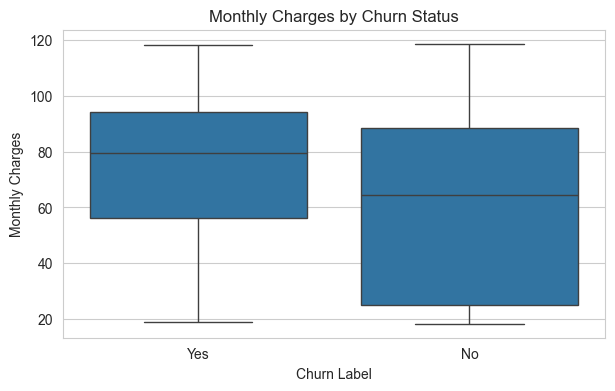

In [24]:
plt.figure(figsize=(7,4))

sns.boxplot(
    data=df_clean,
    x="Churn Label",
    y="Monthly Charges"
)

plt.title("Monthly Charges by Churn Status")

plt.show()

### Insight

Customers who churn tend to have higher monthly charges.

This may indicate customers perceive insufficient value compared with the price they pay.

In [25]:
#Does service type influence churn?
internet_churn = pd.crosstab(
    df_clean["Internet Service"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

internet_churn

Churn Label,No,Yes
Internet Service,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


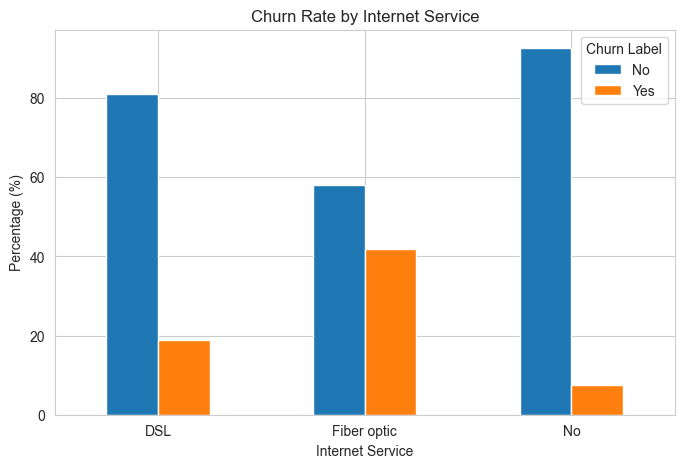

In [26]:
internet_churn.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Churn Rate by Internet Service")
plt.ylabel("Percentage (%)")

plt.xticks(rotation=0)

plt.show()

### Insight

Fiber optic customers show higher churn compared with DSL customers.

Possible reasons:
- higher monthly costs
- service expectations
- competitive alternatives

# 5. Machine Learning Modeling

## Objective

Build a classification model that predicts customer churn risk.

The target variable is:

- 0 = Customer stays
- 1 = Customer churns

Models evaluated:

1. Logistic Regression
2. Random Forest

Evaluation focuses on:
- Recall (ability to find churn customers)
- F1-score
- ROC-AUC
- Accuracy

In [27]:
X = df_clean.drop(
    columns=["Churn Label", "Churn Value"]
)

y = df_clean["Churn Value"]

In [28]:
X.shape, y.shape

((7043, 26), (7043,))

In [29]:
numeric_features = X.select_dtypes(
    include=["int64","float64"]
).columns


categorical_features = X.select_dtypes(
    include=["object"]
).columns

In [30]:
print("Numeric:")
print(numeric_features)

print("\nCategorical:")
print(categorical_features)

Numeric:
Index(['Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges',
       'Total Charges', 'CLTV', 'Number of Services'],
      dtype='object')

Categorical:
Index(['City', 'Gender', 'Senior Citizen', 'Partner', 'Dependents',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Tenure Group'],
      dtype='object')


In [31]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [32]:
y_train.value_counts(normalize=True)*100

Churn Value
0    73.464679
1    26.535321
Name: proportion, dtype: float64

In [33]:
y_test.value_counts(normalize=True)*100

Churn Value
0    73.456352
1    26.543648
Name: proportion, dtype: float64

## Feature Preprocessing

Categorical variables are converted using One-Hot Encoding.

Numerical variables are kept unchanged because Logistic Regression will be tested with the processed features.

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

## Logistic Regression Model

Logistic Regression is selected as the baseline model because it is:
- Suitable for binary classification problems
- Easy to interpret
- Useful for explaining churn drivers to business stakeholders

The target variable:

0 = Customer stayed  
1 = Customer churned

In [51]:
model_features = [
    "Gender",
    "Senior Citizen",
    "Partner",
    "Dependents",
    "Tenure Months",
    "Phone Service",
    "Multiple Lines",
    "Internet Service",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies",
    "Contract",
    "Paperless Billing",
    "Payment Method",
    "Monthly Charges",
    "Total Charges",
    "CLTV",
    "Tenure Group",
    "Number of Services"
]


X = df_clean[model_features]

y = df_clean["Churn Value"]


print(X.shape)
print(y.shape)

(7043, 22)
(7043,)


In [52]:
numeric_features = X.select_dtypes(
    include=["int64","float64"]
).columns


categorical_features = X.select_dtypes(
    include=["object"]
).columns


print("Numeric Features:")
print(numeric_features)


print("\nCategorical Features:")
print(categorical_features)

Numeric Features:
Index(['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV',
       'Number of Services'],
      dtype='object')

Categorical Features:
Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Tenure Group'],
      dtype='object')


## Train-Test Split

The dataset is divided into training and testing sets.

Training data:
Used to teach the model.

Testing data:
Used to evaluate performance on unseen customers.

Stratification is applied because churn classes are imbalanced.

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [54]:
y_train.value_counts(normalize=True)*100

Churn Value
0    73.464679
1    26.535321
Name: proportion, dtype: float64

In [55]:
preprocessor = ColumnTransformer(
    transformers=[
        
        (
            "num",
            "passthrough",
            numeric_features
        ),
        
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [56]:
logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced"
            )
        )
    ]
)

In [57]:
logistic_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  Index(['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV',
       'Number of Services'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Tenure Group'],
      dtype='object'))])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])

In [58]:
y_pred = logistic_model.predict(
    X_test
)


y_prob = logistic_model.predict_proba(
    X_test
)[:,1]

## Model Evaluation

Accuracy alone is not enough because losing customers is the important business problem.

The main metrics considered:

- Recall: How many churn customers were detected
- F1-score: Balance between precision and recall
- ROC-AUC: Overall ability to separate churn and non-churn customers

In [59]:
logistic_results = pd.DataFrame({

    "Model":[
        "Logistic Regression"
    ],

    "Accuracy":[
        accuracy_score(y_test,y_pred)
    ],

    "Precision":[
        precision_score(y_test,y_pred)
    ],

    "Recall":[
        recall_score(y_test,y_pred)
    ],

    "F1 Score":[
        f1_score(y_test,y_pred)
    ],

    "ROC-AUC":[
        roc_auc_score(y_test,y_prob)
    ]

})


logistic_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.750887,0.52007,0.796791,0.629356,0.848996


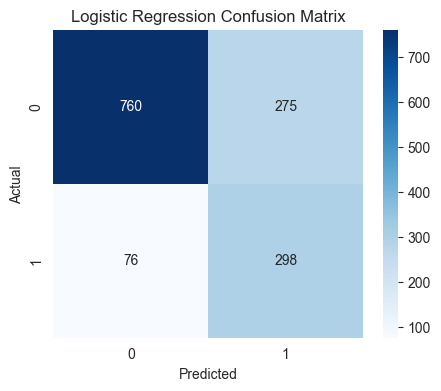

In [60]:
cm = confusion_matrix(
    y_test,
    y_pred
)


plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [61]:
feature_names = logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()


coefficients = logistic_model.named_steps[
    "classifier"
].coef_[0]


feature_importance = pd.DataFrame({

    "Feature": feature_names,

    "Coefficient": coefficients

})

In [62]:
feature_importance.sort_values(
    by="Coefficient",
    ascending=False
).head(10)

,Feature,Coefficient
32,cat__Tenure Group_Loyal Customer,0.420388
10,cat__Multiple Lines_No phone service,0.420075
33,cat__Tenure Group_New Customer,0.408345
30,cat__Payment Method_Electronic check,0.397947
12,cat__Internet Service_Fiber optic,0.386580
28,cat__Paperless Billing_Yes,0.333706
7,cat__Partner_Yes,0.320465
11,cat__Multiple Lines_Yes,0.237117
25,cat__Streaming Movies_Yes,0.237115
23,cat__Streaming TV_Yes,0.227282


In [63]:
feature_importance.sort_values(
    by="Coefficient",
    ascending=True
).head(10)

,Feature,Coefficient
8,cat__Dependents_Yes,-1.756815
27,cat__Contract_Two year,-1.447686
26,cat__Contract_One year,-0.769663
9,cat__Phone Service_Yes,-0.453662
15,cat__Online Security_Yes,-0.300815
21,cat__Tech Support_Yes,-0.262749
4,num__Number of Services,-0.138650
17,cat__Online Backup_Yes,-0.062940
16,cat__Online Backup_No internet service,-0.053322
18,cat__Device Protection_No internet service,-0.053322


### Model Interpretation Summary

The Logistic Regression model indicates that contract type, payment method, internet service, and customer support features are important factors associated with churn risk.

However, coefficients should be interpreted together with exploratory analysis because customer behavior is influenced by multiple interacting factors.

The findings suggest that retention efforts should focus on new customers, month-to-month contracts, fiber optic users, and customers without support services.

In [64]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

In [65]:
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  Index(['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV',
       'Number of Services'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Tenure Group'],
      dtype='object'))])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, random_state=42))])

In [66]:
rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(X_test)[:,1]

In [67]:
rf_results = pd.DataFrame({
    "Model": ["Random Forest"],
    "Accuracy": [accuracy_score(y_test, rf_pred)],
    "Recall": [recall_score(y_test, rf_pred)],
    "F1": [f1_score(y_test, rf_pred)],
    "ROC-AUC": [roc_auc_score(y_test, rf_prob)]
})

rf_results

,Model,Accuracy,Recall,F1,ROC-AUC
0,Random Forest,0.792761,0.502674,0.562874,0.840236


## Model Comparison Table

| Model | Accuracy | Recall | F1 Score | ROC-AUC |
|---|---|---|---|---|
| Logistic Regression | 75.1% | 79.7% | 62.9% | 84.9% |
| Random Forest | 79.3% | 50.3% | 56.3% | 84.0% |

### Final Model Selection

Although Random Forest achieved higher accuracy, Logistic Regression was selected as the final model because it achieved significantly higher recall.

Since the business objective is to identify customers at risk of churn and support retention actions, detecting potential churners is more valuable than maximizing overall prediction accuracy.

The Logistic Regression model provides better business usefulness and interpretability.

In [79]:
df_risk = df_clean.copy()

df_risk.insert(
    0,
    "CustomerID",
    df["CustomerID"]
)

In [80]:
df_risk.head()

,CustomerID,City,Zip Code,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,CLTV,Tenure Group,Number of Services
0,3668-QPYBK,Los Angeles,90003,33.964131,-118.272783,Male,No,No,No,2,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,3239,New Customer,2
1,9237-HQITU,Los Angeles,90005,34.059281,-118.307420,Female,No,No,Yes,2,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,2701,New Customer,0
2,9305-CDSKC,Los Angeles,90006,34.048013,-118.293953,Female,No,No,Yes,8,...,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,5372,New Customer,3
3,7892-POOKP,Los Angeles,90010,34.062125,-118.315709,Female,No,Yes,Yes,28,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,5003,Established Customer,4
4,0280-XJGEX,Los Angeles,90015,34.039224,-118.266293,Male,No,No,Yes,49,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,5340,Loyal Customer,4


In [81]:
df_risk.columns

Index(['CustomerID', 'City', 'Zip Code', 'Latitude', 'Longitude', 'Gender',
       'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label',
       'Churn Value', 'CLTV', 'Tenure Group', 'Number of Services'],
      dtype='object')

In [82]:
df_risk["Churn Probability"] = logistic_model.predict_proba(
    df_clean[model_features]
)[:,1]

In [83]:
df_risk["Risk Level"] = df_risk[
    "Churn Probability"
].apply(risk_category)

In [84]:
df_risk["Retention Priority"] = (
    df_risk["Churn Probability"] *
    df_risk["CLTV"]
)

In [85]:
df_risk[
[
"CustomerID",
"Churn Probability",
"Risk Level",
"Retention Priority"
]
].head()

,CustomerID,Churn Probability,Risk Level,Retention Priority
0,3668-QPYBK,0.592428,Medium Risk,1918.873586
1,9237-HQITU,0.569690,Medium Risk,1538.733209
2,9305-CDSKC,0.697499,High Risk,3746.963175
3,7892-POOKP,0.466037,Medium Risk,2331.582120
4,0280-XJGEX,0.294825,Low Risk,1574.364676


In [86]:
#What is the overall churn situation?
executive_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Churned Customers",
        "Active Customers",
        "Overall Churn Rate"
    ],
    
    "Value": [
        len(df_risk),
        df_risk["Churn Value"].sum(),
        len(df_risk) - df_risk["Churn Value"].sum(),
        df_risk["Churn Value"].mean()
    ]
})


executive_summary

,Metric,Value
0,Total Customers,7043.00000
1,Churned Customers,1869.00000
2,Active Customers,5174.00000
3,Overall Churn Rate,0.26537


In [87]:
#Which customer groups churn more?
churn_analysis = df_risk[
[
"Gender",
"Senior Citizen",
"Tenure Months",
"Tenure Group",
"Internet Service",
"Contract",
"Payment Method",
"Tech Support",
"Monthly Charges",
"Churn Value"
]
]

In [88]:
#Who should the company contact?
risk_analysis = df_risk[
[
"CustomerID",
"Tenure Months",
"Tenure Group",
"Internet Service",
"Contract",
"Payment Method",
"Tech Support",
"Monthly Charges",
"CLTV",
"Churn Probability",
"Risk Level",
"Retention Priority"
]
]

In [89]:
executive_summary.to_csv(
"executive_summary.csv",
index=False
)


churn_analysis.to_csv(
"churn_analysis.csv",
index=False
)


risk_analysis.to_csv(
"risk_analysis.csv",
index=False
)

In [90]:
executive_summary

,Metric,Value
0,Total Customers,7043.00000
1,Churned Customers,1869.00000
2,Active Customers,5174.00000
3,Overall Churn Rate,0.26537


In [91]:
churn_analysis.shape

(7043, 10)

In [92]:
risk_analysis.head()

,CustomerID,Tenure Months,Tenure Group,Internet Service,Contract,Payment Method,Tech Support,Monthly Charges,CLTV,Churn Probability,Risk Level,Retention Priority
0,3668-QPYBK,2,New Customer,DSL,Month-to-month,Mailed check,No,53.85,3239,0.592428,Medium Risk,1918.873586
1,9237-HQITU,2,New Customer,Fiber optic,Month-to-month,Electronic check,No,70.70,2701,0.569690,Medium Risk,1538.733209
2,9305-CDSKC,8,New Customer,Fiber optic,Month-to-month,Electronic check,No,99.65,5372,0.697499,High Risk,3746.963175
3,7892-POOKP,28,Established Customer,Fiber optic,Month-to-month,Electronic check,Yes,104.80,5003,0.466037,Medium Risk,2331.582120
4,0280-XJGEX,49,Loyal Customer,Fiber optic,Month-to-month,Bank transfer (automatic),No,103.70,5340,0.294825,Low Risk,1574.364676


In [94]:
model_performance = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        0.750887,
        0.792761
    ],
    "Recall": [
        0.796791,
        0.502674
    ],
    "F1 Score": [
        0.629356,
        0.562874
    ],
    "ROC-AUC": [
        0.848996,
        0.840236
    ]
})


model_performance

,Model,Accuracy,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.750887,0.796791,0.629356,0.848996
1,Random Forest,0.792761,0.502674,0.562874,0.840236


In [95]:
model_performance.to_csv(
    "model_performance.csv",
    index=False
)

In [99]:
powerbi_dataset = df_risk.copy()

powerbi_dataset.to_csv(
    "customer_churn_powerbi.csv",
    index=False
)

In [100]:
powerbi_dataset.shape

(7043, 32)

In [101]:
powerbi_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 32 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CustomerID          7043 non-null   object 
 1   City                7043 non-null   object 
 2   Zip Code            7043 non-null   int64  
 3   Latitude            7043 non-null   float64
 4   Longitude           7043 non-null   float64
 5   Gender              7043 non-null   object 
 6   Senior Citizen      7043 non-null   object 
 7   Partner             7043 non-null   object 
 8   Dependents          7043 non-null   object 
 9   Tenure Months       7043 non-null   int64  
 10  Phone Service       7043 non-null   object 
 11  Multiple Lines      7043 non-null   object 
 12  Internet Service    7043 non-null   object 
 13  Online Security     7043 non-null   object 
 14  Online Backup       7043 non-null   object 
 15  Device Protection   7043 non-null   object 
 16  Tech S

In [102]:
powerbi_dataset.head()

,CustomerID,City,Zip Code,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,...,Monthly Charges,Total Charges,Churn Label,Churn Value,CLTV,Tenure Group,Number of Services,Churn Probability,Risk Level,Retention Priority
0,3668-QPYBK,Los Angeles,90003,33.964131,-118.272783,Male,No,No,No,2,...,53.85,108.15,Yes,1,3239,New Customer,2,0.592428,Medium Risk,1918.873586
1,9237-HQITU,Los Angeles,90005,34.059281,-118.307420,Female,No,No,Yes,2,...,70.70,151.65,Yes,1,2701,New Customer,0,0.569690,Medium Risk,1538.733209
2,9305-CDSKC,Los Angeles,90006,34.048013,-118.293953,Female,No,No,Yes,8,...,99.65,820.50,Yes,1,5372,New Customer,3,0.697499,High Risk,3746.963175
3,7892-POOKP,Los Angeles,90010,34.062125,-118.315709,Female,No,Yes,Yes,28,...,104.80,3046.05,Yes,1,5003,Established Customer,4,0.466037,Medium Risk,2331.582120
4,0280-XJGEX,Los Angeles,90015,34.039224,-118.266293,Male,No,No,Yes,49,...,103.70,5036.30,Yes,1,5340,Loyal Customer,4,0.294825,Low Risk,1574.364676


In [103]:
powerbi_dataset["Risk Level"].value_counts()

Risk Level
Low Risk       3228
High Risk      2359
Medium Risk    1456
Name: count, dtype: int64